In [1]:
import numpy as np
import matplotlib.pyplot as plt
import timeit

## Aufgabenstellung

Implementiere eine eigene diskrete Fouriertransformation. Einerseits mittels einer Reihenapproximation zu den gegebenen Daten und andererseits berechne die Fourierkoeffizienten mittels numerischer Integration. 

Teste deine beiden Implementationen mit dem Signal s(t)=2+5*sin(t)+3*cos(3*t) im Zeitintervall 
[0,2*pi] mit 64 (äquidistanten) Messwerten. 
Skizziere jeweils das erhaltene Amplitudenspektrum. 
Vergleiche deine Ergebnisse mit den von Python zur Verfügung gestellten Funktionen (numpy.fft bzw scipy.fft) – auch hinsichtlich der Performance. 

### 1. Reihenapproximation (DFT-Formel)

Diskrete Fouriertransformation in Matrixform unter Verwendung der Euler'sche Formel:
    
    e^{ix} = cos(x) + i sin(x)
    cos(x)  = (e^{ix} + e^{-ix}) / 2
    sin(x)  = (e^{ix} - e^{-ix}) / (2i)

In [2]:
def dft_euler_sin_cos(signal):
    signal = np.array(signal, dtype=float)
    n = len(signal)
    
    x = np.zeros(n, dtype=complex)
    
    for k in range(n):
        for m in range(n):
            angle = 2 * np.pi * k * m / n
            # e ^ {ix} = cos(x) + i sin(x)
            exp_term = np.cos(angle) - 1j * np.sin(angle)
            
            x[k] += signal[m] * exp_term
        
    return x 


### Numerische Integration

Für kontinuierliche Fourier-Koeffizienten gilt:

**Kosinus-Koeffizient:**
$$a_k = \frac{2}{T} \int_0^T f(t) \cdot \cos\left(k \cdot \frac{2\pi}{T} \cdot t\right) \, dt$$

**Sinus-Koeffizient:**
$$b_k = \frac{2}{T} \int_0^T f(t) \cdot \sin\left(k \cdot \frac{2\pi}{T} \cdot t\right) \, dt$$

**DC-Komponente** (Mittelwert, $k=0$):
$$a_0 = \frac{1}{T} \int_0^T f(t) \, dt$$

Die Integrale werden numerisch mittels der **Trapezregel** approximiert.

**Komplexer Koeffizient:**
$$X_k = a_k - i \cdot b_k$$

In [3]:
def dft_numerische_integration(t, signal, max_freq=32):
    n = len(signal)
    x = np.zeros(max_freq, dtype=complex)
    T = t[-1] - t[0]
    
    a_0 = (1/T) * np.trapezoid(signal, t)
    x[0] = a_0
    
    for k in range(1, max_freq ):
        # a_k = (2/T) * integral(f(t) * cos(k * 2π/T * t)) dt
        omega = k * 2 * np.pi / T
        integrand_cos = np.cos(omega * t) * signal
        a_k = (2/T) * np.trapezoid(integrand_cos, t)
       
        # b_k = (2/T) * integral(f(t) * sin(k * 2π/T * t)) dt
        integrand_sin = np.sin(omega * t) * signal
        b_k = (2/T) * np.trapezoid(integrand_sin, t)
        
        # X_k = a_k - i*b_k
        x[k] = a_k -1j * b_k
    return x

Erzeugung eines Testsignals wie in der Aufgabe definiert: s(t) = 2 + 5*sin(t) + 3*cos(3*t)

In [4]:
N = 64
t = np.linspace(0, 2*np.pi, N, endpoint=False)
signal = 2 + 5*np.sin(t) + 3*np.cos(3*t)

Berechnung mit beiden Methoden:

In [5]:
print("Methode 1: Reihenapproximation (Euler'sche-Formel)")
# Führe mehrmals aus für genauere Messung
number = 10  # Anzahl Wiederholungen
time_reihe = timeit.timeit(lambda: dft_euler_sin_cos(signal), number=number) / number
X_reihe = dft_euler_sin_cos(signal)  # Einmal für Ergebnis
print(f"Berechnungszeit: {time_reihe:.6f} Sekunden (Durchschnitt über {number} Läufe)")

print("Methode 2: Numerische Integration")
time_integration = timeit.timeit(lambda: dft_numerische_integration(t, signal, max_freq=N//2), number=number) / number
X_integration = dft_numerische_integration(t, signal, max_freq=N//2)  # Einmal für Ergebnis
print(f"Berechnungszeit: {time_integration:.6f} Sekunden (Durchschnitt über {number} Läufe)")

print("Vergleich: Numpy FFT")
time_numpy = timeit.timeit(lambda: np.fft.fft(signal), number=number) / number
X_numpy = np.fft.fft(signal)  # Einmal für Ergebnis
print(f"Berechnungszeit: {time_numpy:.6f} Sekunden (Durchschnitt über {number} Läufe)")

Methode 1: Reihenapproximation (Euler'sche-Formel)
Berechnungszeit: 0.007858 Sekunden (Durchschnitt über 10 Läufe)
Methode 2: Numerische Integration
Berechnungszeit: 0.000457 Sekunden (Durchschnitt über 10 Läufe)
Vergleich: Numpy FFT
Berechnungszeit: 0.000240 Sekunden (Durchschnitt über 10 Läufe)


Amplitudenspektren werden berechnet

In [6]:
# Nur positive Frequenzen betrachten
freqs = np.fft.fftfreq(N, d=(2*np.pi/N))
positive_freqs = freqs[:N//2]

# Amplituden (Betrag der komplexen Koeffizienten)
amp_reihe = np.abs(X_reihe[:N//2]) / N * 2  # Normierung für DFT
amp_integration = np.abs(X_integration)  # a_k und b_k sind bereits richtig normiert
amp_numpy = np.abs(X_numpy[:N//2]) / N * 2  # Normierung für NumPy FFT

# DC-Komponente (k=0) separat normieren
amp_reihe[0] = np.abs(X_reihe[0]) / N
amp_integration[0] = np.abs(X_integration[0])  # a_0 ist bereits korrekt
amp_numpy[0] = np.abs(X_numpy[0]) / N

Ergebnisse ausgeben

In [7]:
print("Erwartete Frequenzkomponenten:")
print("DC (f=0):     Amplitude = 2")
print("f=1 (sin):    Amplitude = 5")
print("f=3 (cos):    Amplitude = 3")

print("Gefundene Frequenzkomponenten:")

# Finde dominante Frequenzen (Amplitude > 0.5)
threshold = 0.5

print("\nReihenapproximation:")
for i, amp in enumerate(amp_reihe):
    if amp > threshold:
        print(f"  Frequenz {i}: Amplitude = {amp:.4f}")

print("\nNumerische Integration:")
for i, amp in enumerate(amp_integration):
    if amp > threshold:
        print(f"  Frequenz {i}: Amplitude = {amp:.4f}")

print("\nNumpy FFT:")
for i, amp in enumerate(amp_numpy):
    if amp > threshold:
        print(f"  Frequenz {i}: Amplitude = {amp:.4f}")

Erwartete Frequenzkomponenten:
DC (f=0):     Amplitude = 2
f=1 (sin):    Amplitude = 5
f=3 (cos):    Amplitude = 3
Gefundene Frequenzkomponenten:

Reihenapproximation:
  Frequenz 0: Amplitude = 2.0000
  Frequenz 1: Amplitude = 5.0000
  Frequenz 3: Amplitude = 3.0000

Numerische Integration:
  Frequenz 0: Amplitude = 1.9573
  Frequenz 1: Amplitude = 5.0379
  Frequenz 3: Amplitude = 2.9756

Numpy FFT:
  Frequenz 0: Amplitude = 2.0000
  Frequenz 1: Amplitude = 5.0000
  Frequenz 3: Amplitude = 3.0000


Performance anzeigen

In [8]:
print("Performance-Vergleich:")
# Zeige absolute Zeiten
print(f"Reihenapproximation:     {time_reihe:.6f} s")
print(f"Numerische Integration:  {time_integration:.6f} s")
print(f"Numpy FFT:               {time_numpy:.6f} s")

# Berechne Faktoren nur wenn möglich
print("\nRelative Performance:")
if time_numpy > 0:
    print(f"  Reihenapproximation ist {time_reihe/time_numpy:.1f}x langsamer als Numpy FFT")
    print(f"  Numerische Integration ist {time_integration/time_numpy:.1f}x langsamer als Numpy FFT")
    
if time_integration > 0:
    print(f"  Reihenapproximation ist {time_reihe/time_integration:.1f}x langsamer als Numerische Integration")
else:
    print(f"  Numerische Integration war zu schnell für präzise Messung (<1 ms)")
    
print("\nNumpy FFT nutzt optimierte C-Implementierung (FFT-Algorithmus)")
print("Eigene Implementierungen sind langsamer, zeigen aber das Verständnis der Mathematik")

Performance-Vergleich:
Reihenapproximation:     0.007858 s
Numerische Integration:  0.000457 s
Numpy FFT:               0.000240 s

Relative Performance:
  Reihenapproximation ist 32.7x langsamer als Numpy FFT
  Numerische Integration ist 1.9x langsamer als Numpy FFT
  Reihenapproximation ist 17.2x langsamer als Numerische Integration

Numpy FFT nutzt optimierte C-Implementierung (FFT-Algorithmus)
Eigene Implementierungen sind langsamer, zeigen aber das Verständnis der Mathematik


Ergebnisse visualisieren

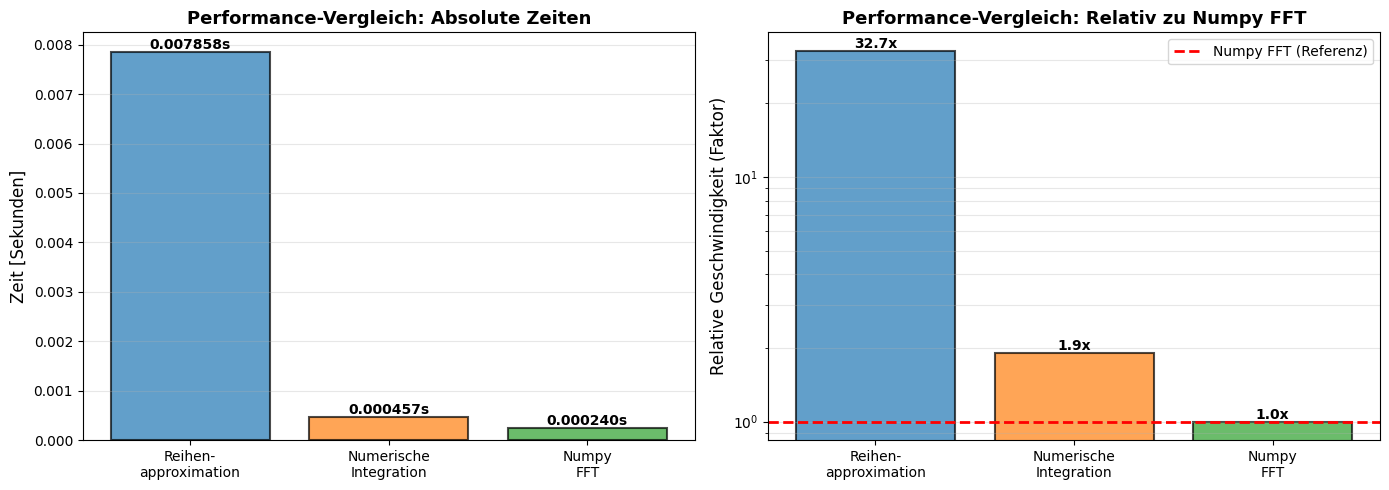

In [9]:
fig_perf, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Absolute Zeiten (Balkendiagramm)
methods = ['Reihen-\napproximation', 'Numerische\nIntegration', 'Numpy\nFFT']
times = [time_reihe, time_integration, time_numpy]
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

bars = ax1.bar(methods, times, color=colors, alpha=0.7, edgecolor='black', linewidth=1.5)
ax1.set_ylabel('Zeit [Sekunden]', fontsize=12)
ax1.set_title('Performance-Vergleich: Absolute Zeiten', fontsize=13, fontweight='bold')
ax1.grid(axis='y', alpha=0.3)

# Werte über den Balken
for bar, time_val in zip(bars, times):
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height,
             f'{time_val:.6f}s', ha='center', va='bottom', fontsize=10, fontweight='bold')

# Plot 2: Relative Performance (logarithmische Skala)
if time_numpy > 0 and time_integration > 0:
    relative_times = [time_reihe/time_numpy, time_integration/time_numpy, 1.0]
    
    bars2 = ax2.bar(methods, relative_times, color=colors, alpha=0.7, edgecolor='black', linewidth=1.5)
    ax2.set_ylabel('Relative Geschwindigkeit (Faktor)', fontsize=12)
    ax2.set_title('Performance-Vergleich: Relativ zu Numpy FFT', fontsize=13, fontweight='bold')
    ax2.set_yscale('log')
    ax2.grid(axis='y', alpha=0.3, which='both')
    ax2.axhline(y=1, color='red', linestyle='--', linewidth=2, label='Numpy FFT (Referenz)')
    
    # Werte über den Balken
    for bar, rel_t in zip(bars2, relative_times):
        height = bar.get_height()
        ax2.text(bar.get_x() + bar.get_width()/2., height,
                 f'{rel_t:.1f}x', ha='center', va='bottom', fontsize=10, fontweight='bold')
    
    ax2.legend(fontsize=10)

plt.tight_layout()
plt.show()

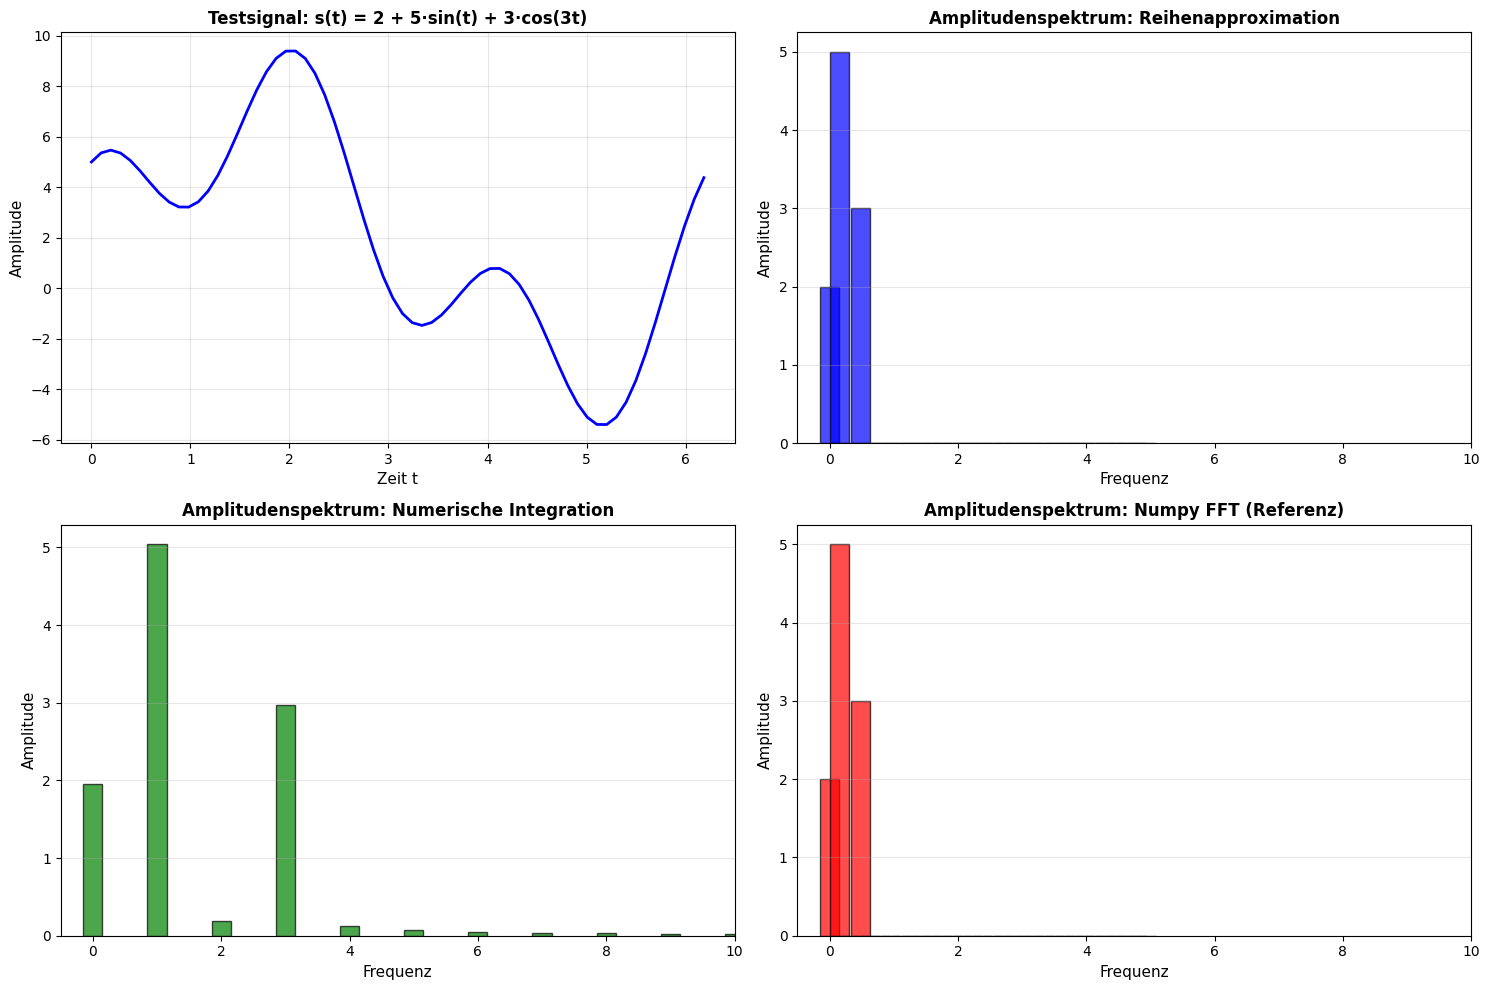

In [10]:
fig_amp, axes = plt.subplots(2, 2, figsize=(15, 10))

# Original Signal
axes[0, 0].plot(t, signal, 'b-', linewidth=2)
axes[0, 0].set_xlabel('Zeit t', fontsize=11)
axes[0, 0].set_ylabel('Amplitude', fontsize=11)
axes[0, 0].set_title('Testsignal: s(t) = 2 + 5·sin(t) + 3·cos(3t)', fontsize=12, fontweight='bold')
axes[0, 0].grid(True, alpha=0.3)

# Amplitudenspektrum: Reihenapproximation
axes[0, 1].bar(positive_freqs, amp_reihe, width=0.3, color='blue', alpha=0.7, edgecolor='black')
axes[0, 1].set_xlabel('Frequenz', fontsize=11)
axes[0, 1].set_ylabel('Amplitude', fontsize=11)
axes[0, 1].set_title('Amplitudenspektrum: Reihenapproximation', fontsize=12, fontweight='bold')
axes[0, 1].set_xlim(-0.5, 10)
axes[0, 1].grid(True, alpha=0.3, axis='y')

# Amplitudenspektrum: Numerische Integration
axes[1, 0].bar(range(len(amp_integration)), amp_integration, width=0.3, color='green', alpha=0.7, edgecolor='black')
axes[1, 0].set_xlabel('Frequenz', fontsize=11)
axes[1, 0].set_ylabel('Amplitude', fontsize=11)
axes[1, 0].set_title('Amplitudenspektrum: Numerische Integration', fontsize=12, fontweight='bold')
axes[1, 0].set_xlim(-0.5, 10)
axes[1, 0].grid(True, alpha=0.3, axis='y')

# Amplitudenspektrum: NumPy FFT
axes[1, 1].bar(positive_freqs, amp_numpy, width=0.3, color='red', alpha=0.7, edgecolor='black')
axes[1, 1].set_xlabel('Frequenz', fontsize=11)
axes[1, 1].set_ylabel('Amplitude', fontsize=11)
axes[1, 1].set_title('Amplitudenspektrum: Numpy FFT (Referenz)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlim(-0.5, 10)
axes[1, 1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()